In [151]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import numpy as np
np.linalg.norm(np.ones(2))   # macOS: wake up numpy's maths library before torch loads
import torch                 # noqa: F401  (deepshape2 imports it; it must load before galsim)
import galsim                # noqa: F401

import time
import warnings

import logging

import ska_sdp_scripting
import ska_ser_logging

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams["figure.dpi"] = 110


DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
print("networks will run on:", DEVICE)



def show(ax, img, title, cmap="inferno", **kw):
    # Small helper so the plotting code below stays short.
    ax.imshow(img, origin="lower", cmap=cmap, **kw)
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])

networks will run on: mps


In [107]:
#open and examine the data fits files
import os
import glob
import astropy.io.fits as fits
#import lognorm
from matplotlib.colors import LogNorm

fits_filename = "ska_data/SKAMid_B2_1000h_v3.fits"
with fits.open(fits_filename) as hdul:
    # Print file structure (tells you where the image data sits)
    hdul.info() 
    
    # Extract the image array from the Primary HDU (usually index 0)
    image_data = hdul[0].data

Filename: ska_data/SKAMid_B2_1000h_v3.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     113   (32768, 32768, 1, 1)   float32   


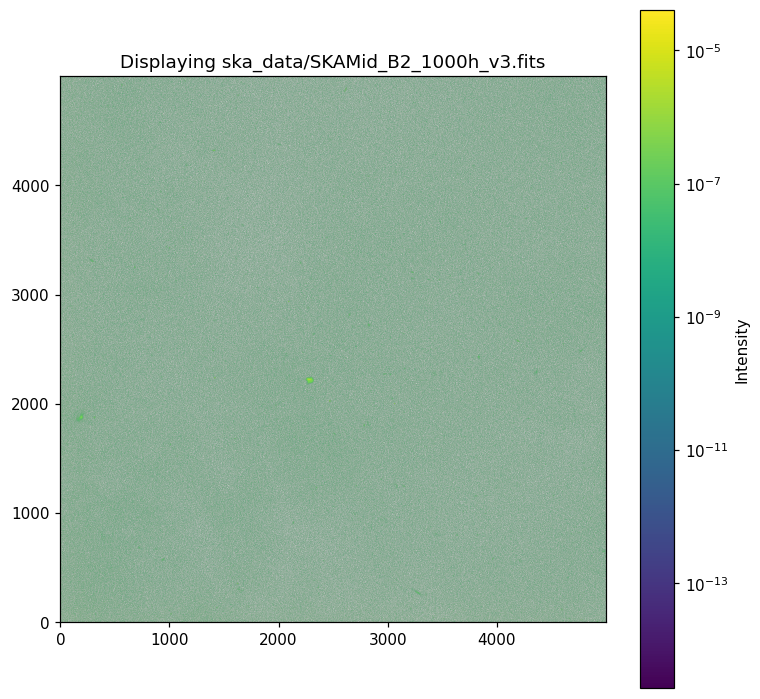

In [108]:
# 2. Display the image
plt.figure(figsize=(8, 8))
plt.imshow(
    image_data[0, 0, :5000, :5000],  
    origin='lower',       # Puts (0,0) at bottom-left (standard for astronomy)
    norm=LogNorm()        # Improves contrast for high dynamic range objects
)

plt.colorbar(label='Intensity')
plt.title(f"Displaying {fits_filename}")
plt.show()

In [109]:
# Load the SDC1 1.4 GHz truth catalogue (no header row in the file; 12 whitespace-separated columns)
truth_cols = [
    "ID",        # source ID
    "RA_core",   # [deg] RA of the source core
    "DEC_core",  # [deg] Dec of the source core
    "RA_cent",   # [deg] RA of the source centroid
    "DEC_cent",  # [deg] Dec of the source centroid
    "FLUX",      # [Jy] integrated flux density (intrinsic, i.e. before primary-beam attenuation)
    "core_frac", # [none] core / total integrated flux
    "BMAJ",      # [arcsec] major axis
    "BMIN",      # [arcsec] minor axis
    "PA",        # [deg] position angle
    "SIZE",      # 1 = LAS, 2 = Gaussian, 3 = Exponential
    "CLASS",     # 1 = SS-AGN, 2 = FS-AGN, 3 = SFG
]
truth = pd.read_csv("ska_data/True1400v2.txt", sep=r"\s+", header=None, names=truth_cols)

# One source has NaN centroid coordinates; fall back to its core position
no_cent = truth["RA_cent"].isna()
truth.loc[no_cent, "RA_cent"] = truth.loc[no_cent, "RA_core"]
truth.loc[no_cent, "DEC_cent"] = truth.loc[no_cent, "DEC_core"]

CLASS_NAMES = {1: "SS-AGN", 2: "FS-AGN", 3: "SFG"}
SIZE_NAMES = {1: "LAS", 2: "Gaussian", 3: "Exponential"}

print(f"{len(truth):,} sources")
pd.crosstab(truth["CLASS"].map(CLASS_NAMES), truth["SIZE"].map(SIZE_NAMES))

1,377,375 sources


SIZE,Exponential,Gaussian,LAS
CLASS,,,
FS-AGN,0,28187,0
SFG,56094,1186826,0
SS-AGN,0,1039,105229


In [111]:
from astropy.wcs import WCS

header = fits.getheader(fits_filename)
wcs = WCS(header).celestial          #

# RA in the catalogue is negative, the WCS expects 0–360
ra  = truth["RA_cent"].values % 360
dec = truth["DEC_cent"].values

truth["x"], truth["y"] = wcs.world_to_pixel_values(ra, dec)

### Sanity check: cutouts around a few catalogue sources

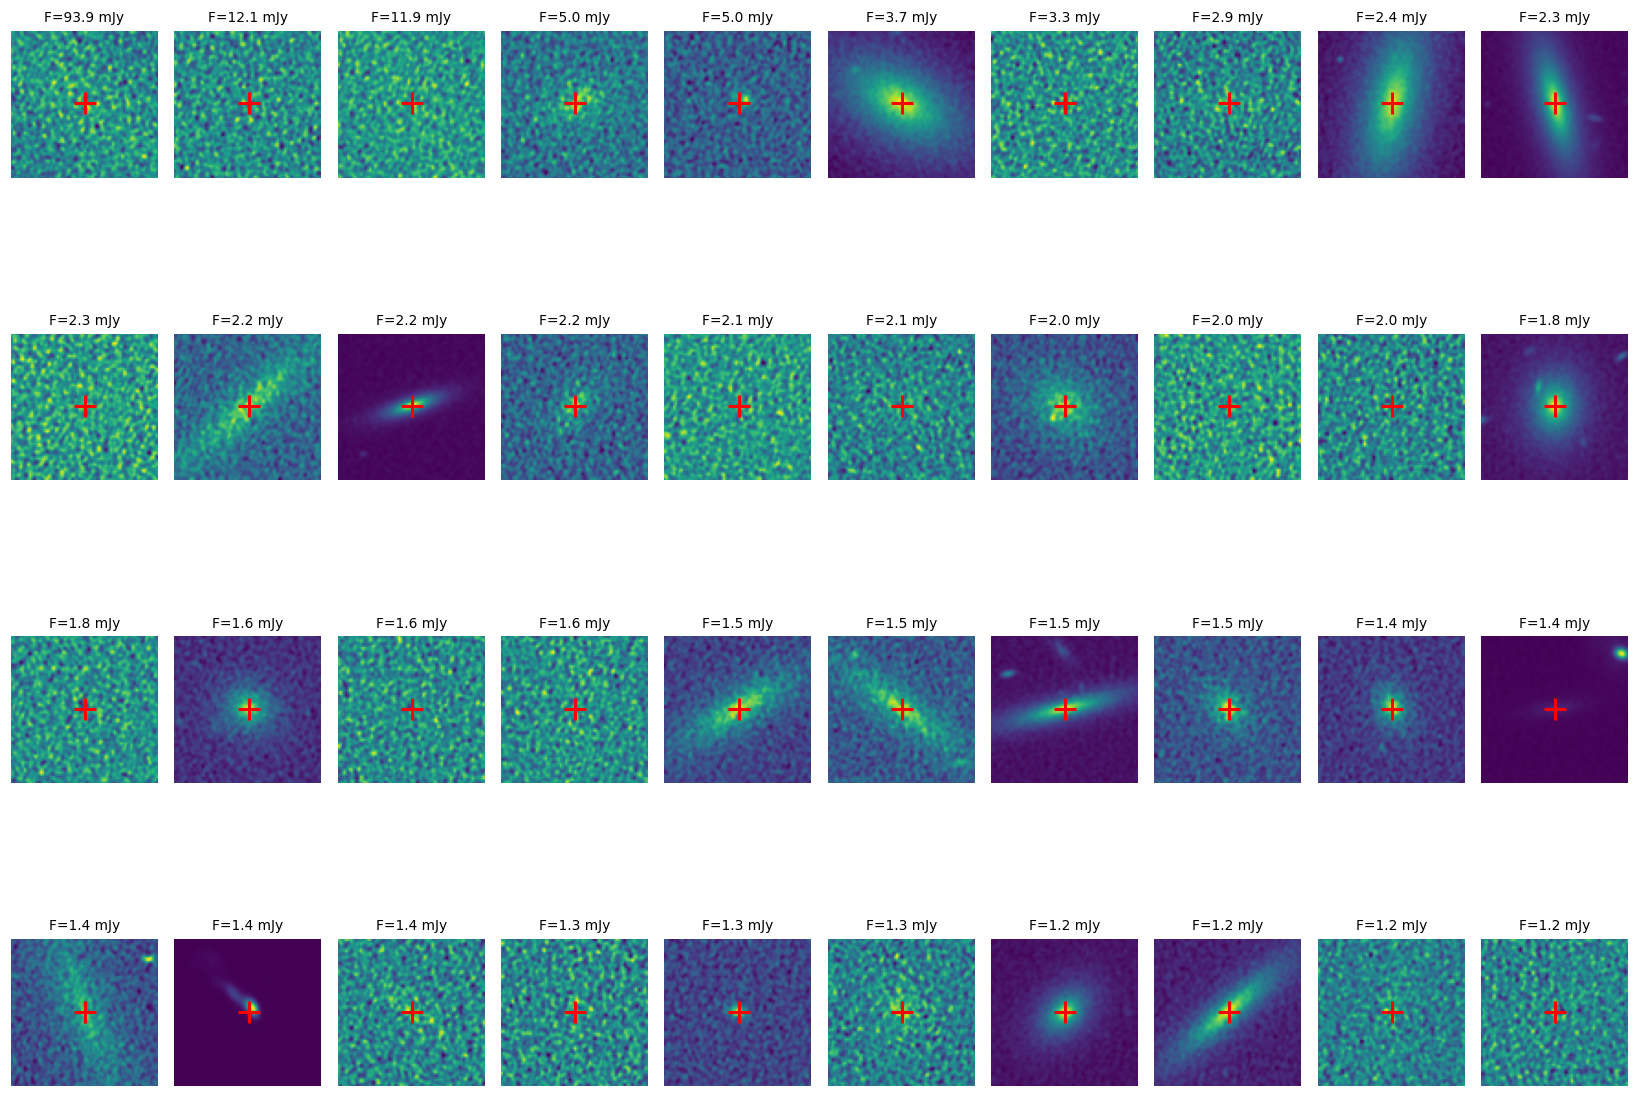

In [112]:
img = image_data[0, 0]
#lets filter only SFGs

truth_sfg = truth[truth["CLASS"] == 3]
brightest = truth_sfg.sort_values("FLUX", ascending=False).head(40)

h = 40  # half-width of cutout in pixels
fig, axes = plt.subplots(4, 10, figsize=(15, 12))

for ax, (_, src) in zip(axes.flat, brightest.iterrows()):
    x, y = int(round(src["x"])), int(round(src["y"]))
    cut = img[y-h:y+h, x-h:x+h]

    ax.imshow(cut, origin="lower")
    ax.plot(h, h, "r+", markersize=15, markeredgewidth=2)
    ax.set_title(f"F={src['FLUX']*1e3:.1f} mJy", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [113]:
from astropy.stats import sigma_clipped_stats
mean, median, sigma = sigma_clipped_stats(block, sigma=3)

print(f"Mean: {1e6* mean:.3e} mJy, Median: {1e6*median:.3e} mJy, Sigma: {1e6*sigma:.3e} mJy")

Mean: -3.271e-02 mJy, Median: -3.372e-02 mJy, Sigma: 6.863e-02 mJy


In [114]:
truth_sfg = truth[truth["CLASS"] == 3].copy()

xc = np.round(truth_sfg["x"].values).astype(int)
yc = np.round(truth_sfg["y"].values).astype(int)

# max over a 5x5 box (~1 beam) around each position, vectorised
r = 2
peak = np.full(len(truth_sfg), -np.inf)
for dy in range(-r, r + 1):
    for dx in range(-r, r + 1):
        yy = np.clip(yc + dy, 0, img.shape[0] - 1)
        xx = np.clip(xc + dx, 0, img.shape[1] - 1)
        peak = np.maximum(peak, img[yy, xx])

truth_sfg["peak"] = peak
truth_sfg["psnr"] = peak / sigma

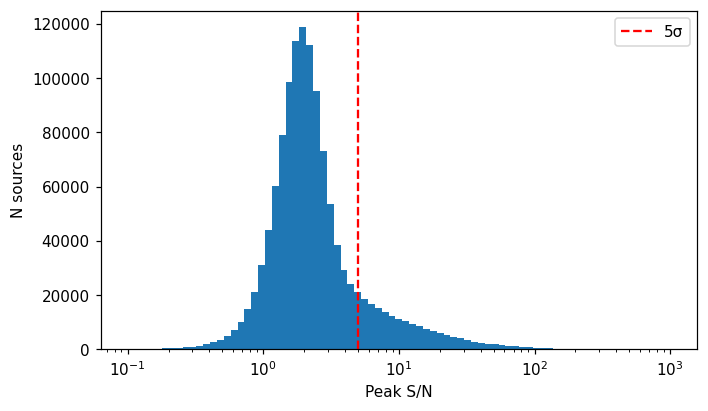

183489 SFGs above 5σ


In [115]:
plt.figure(figsize=(7, 4))
plt.hist(truth_sfg["psnr"], bins=np.logspace(-1, 3, 80))
plt.xscale("log")
plt.axvline(5, color="r", ls="--", label="5σ")
plt.xlabel("Peak S/N"); plt.ylabel("N sources"); plt.legend()
plt.show()

print((truth_sfg["psnr"] > 5).sum(), "SFGs above 5σ")

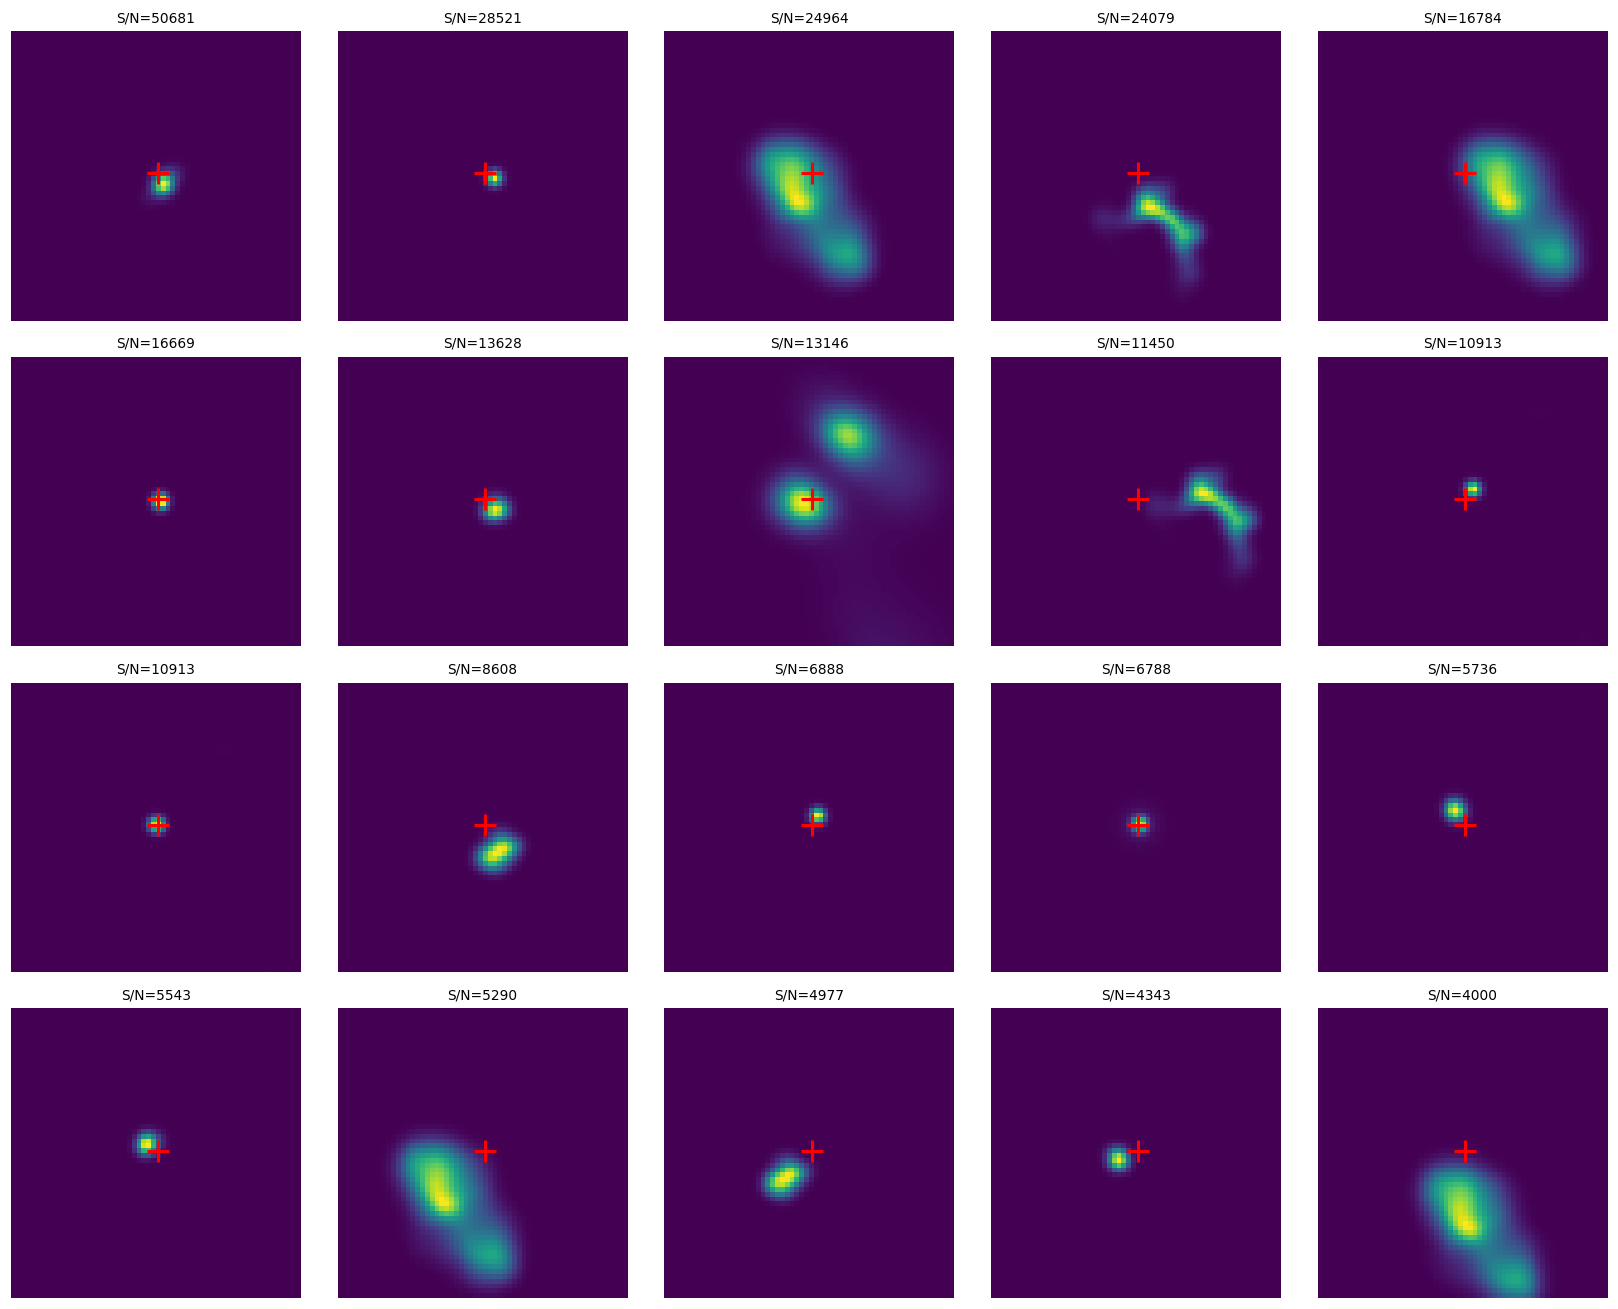

In [120]:
top = truth_sfg.sort_values("psnr", ascending=False).head(20)

h = 30
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
for ax, (_, src) in zip(axes.flat, top.iterrows()):
    x, y = int(round(src["x"])), int(round(src["y"]))
    ax.imshow(img[y-h:y+h, x-h:x+h], origin="lower")
    ax.plot(h, h, "r+", markersize=15, markeredgewidth=2)
    ax.set_title(f"S/N={src['psnr']:.0f}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [163]:
# A source's peak (Jy/beam) can't exceed its integrated flux (Jy) for a beam-sized
# or larger source, so peak >> FLUX means something else is contributing
truth_sfg["peak_over_flux"] = truth_sfg["peak"] / truth_sfg["FLUX"]
contaminated = truth_sfg["peak_over_flux"] > 1.5

print(f"{contaminated.sum():,}")

193,599


In [ ]:
from scipy.spatial import cKDTree

# neighbour search in pixel space over the FULL catalogue
tree = cKDTree(np.c_[truth["x"], truth["y"]])
pairs = tree.query_ball_point(np.c_[truth_sfg["x"], truth_sfg["y"]], r=20)  # 20 px ≈ 5"

flux_all = truth["FLUX"].values
isolated = np.array([
    np.sum(flux_all[idx] > f) == 0          # no brighter neighbour within r
    for idx, f in zip(pairs, truth_sfg["FLUX"].values)
])
truth_sfg["isolated"] = isolated

450272


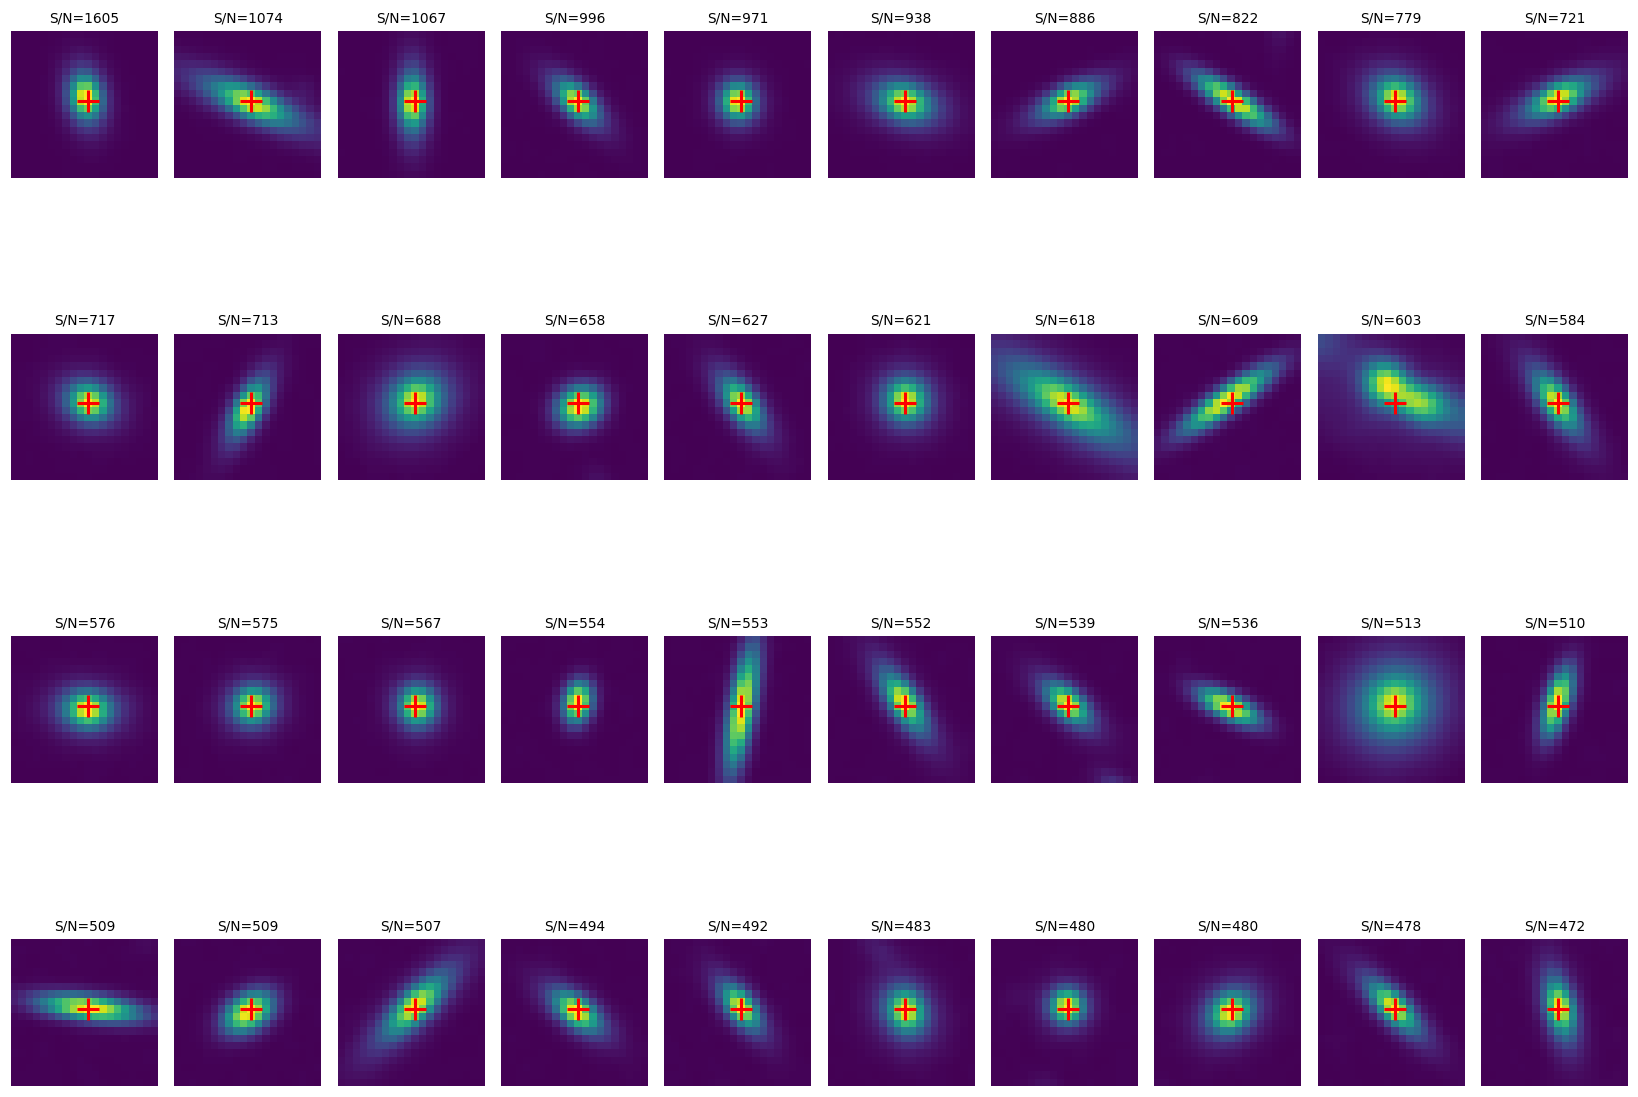

In [123]:
clean = truth_sfg[~contaminated & truth_sfg["isolated"]]
top = clean.sort_values("psnr", ascending=False).head(40)

print(len(clean))

h = 10
fig, axes = plt.subplots(4, 10, figsize=(15, 12))
for ax, (_, src) in zip(axes.flat, top.iterrows()):
    x, y = int(round(src["x"])), int(round(src["y"]))
    ax.imshow(img[y-h:y+h, x-h:x+h], origin="lower")
    ax.plot(h, h, "r+", markersize=15, markeredgewidth=2)
    ax.set_title(f"S/N={src['psnr']:.0f}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

450272


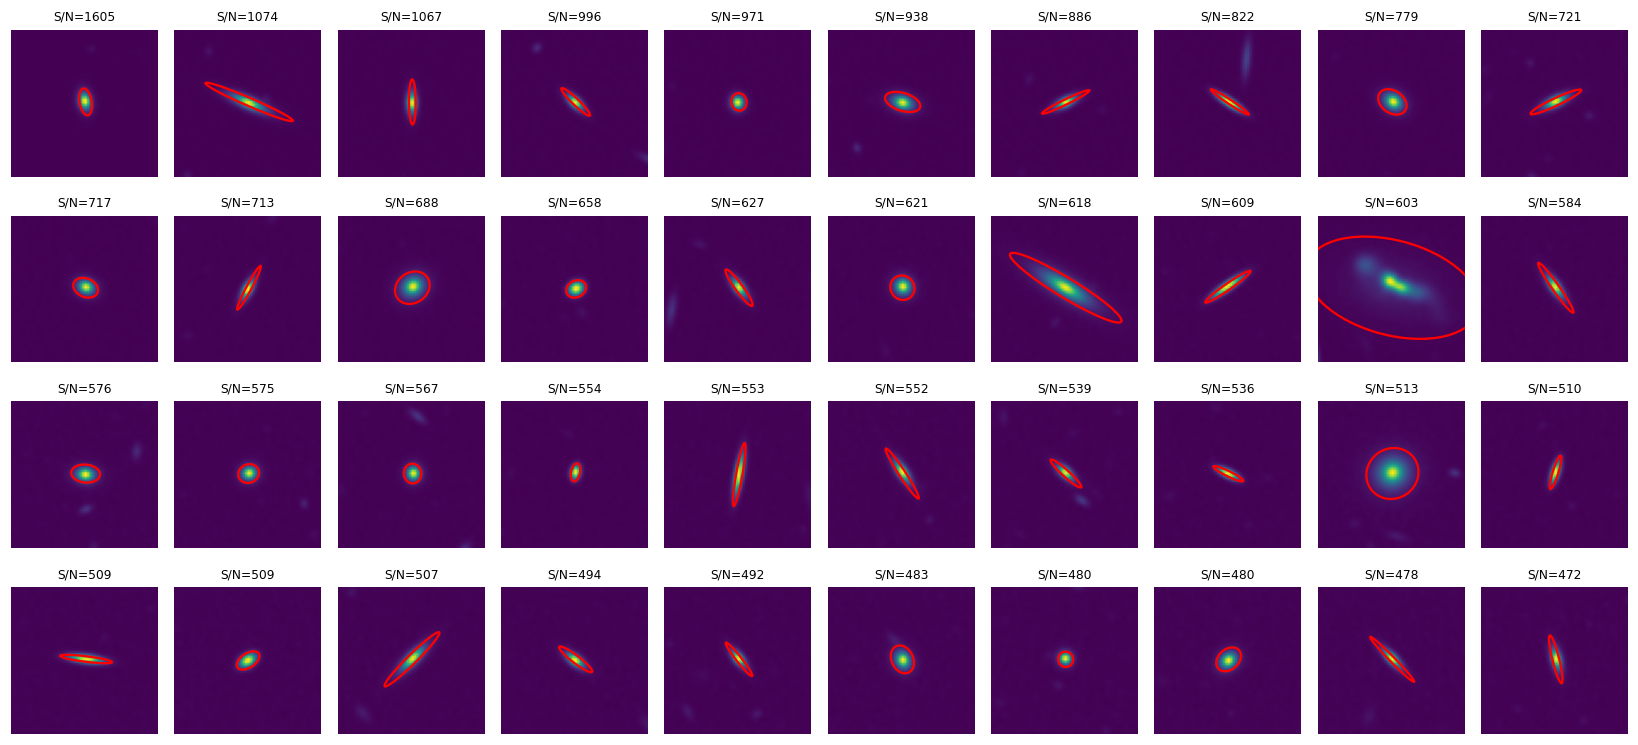

In [ ]:
from matplotlib.patches import Ellipse

clean = truth_sfg[~contaminated & truth_sfg["isolated"]].copy()

# standardise shape column names (rename silently ignores keys that aren't there)
clean = clean.rename(columns={"BMAJ": "B_MAJ", "BMIN": "B_MIN",
                              "b_maj": "B_MAJ", "b_min": "B_MIN", "pa": "PA"})

top = clean.sort_values("psnr", ascending=False).head(40)
print(len(clean))

pix_arcsec = abs(header["CDELT2"]) * 3600

h = 30
fig, axes = plt.subplots(4, 10, figsize=(15, 7))
for ax, (_, src) in zip(axes.flat, top.iterrows()):
    xi, yi = int(round(src["x"])), int(round(src["y"]))
    ax.imshow((img[yi-h:yi+h, xi-h:xi+h]), origin="lower")

    cx, cy = h + (src["x"] - xi), h + (src["y"] - yi)
    a, b = src["B_MAJ"] / pix_arcsec, src["B_MIN"] / pix_arcsec
    ax.add_patch(Ellipse((cx, cy), 2*a, 2*b, angle=-src["PA"],
                         fill=False, color="r", lw=1.5))

    ax.set_xlim(-0.5, 2*h - 0.5); ax.set_ylim(-0.5, 2*h - 0.5)
    ax.set_title(f"S/N={src['psnr']:.0f}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [146]:
psf_file = "ska_data/SynthesBeam_B2.fits"

with fits.open(psf_file) as hdul:
    hdul.info()
    psf_hdr = hdul[0].header
    psf_full = np.squeeze(hdul[0].data)        # drop any singleton freq/Stokes axes

print(psf_full.shape, psf_full.dtype)
print("CDELT2 (arcsec):", abs(psf_hdr.get("CDELT2", np.nan)) * 3600)
print("BMAJ/BMIN (arcsec):", psf_hdr.get("BMAJ", np.nan) * 3600, psf_hdr.get("BMIN", np.nan) * 3600)

Filename: ska_data/SynthesBeam_B2.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     106   (32768, 32768, 1)   float32   
(32768, 32768) >f4
CDELT2 (arcsec): 0.24169929895116
BMAJ/BMIN (arcsec): 0.600024301092 0.600024301092


peak at (16384, 16384) value 1.0000001


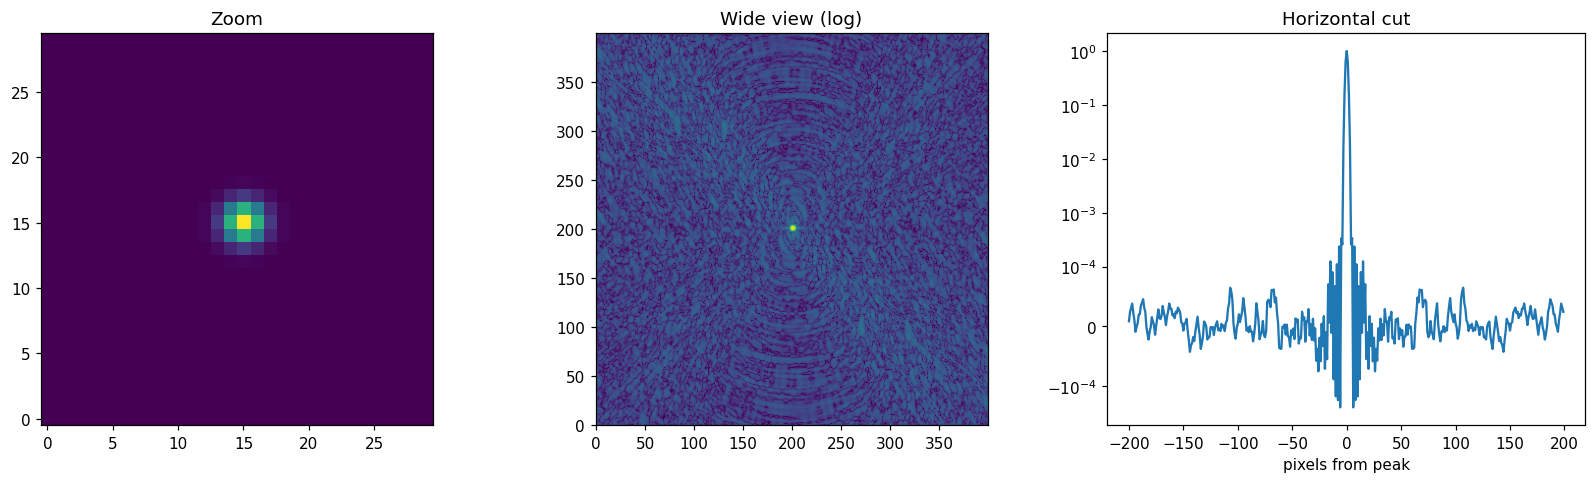

In [177]:
# Find the peak rather than assuming it's exactly central
py, px = np.unravel_index(np.argmax(psf_full), psf_full.shape)
print("peak at", (px, py), "value", psf_full[py, px])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. core, linear
h = 15
axes[0].imshow(psf_full[py-h:py+h, px-h:px+h], origin="lower")
axes[0].set_title("Zoom")

# 2. wider view, log of |PSF| to show sidelobes
H = 200
axes[1].imshow(np.abs(psf_full[py-H:py+H, px-H:px+H]), origin="lower", norm=LogNorm(vmin=1e-6))
axes[1].set_title("Wide view (log)")

# 3. 1D cut through the peak
cut =  psf_full[py, px-H:px+H]
axes[2].plot(np.arange(-H, H), cut)
axes[2].set_yscale("symlog", linthresh=1e-4)
axes[2].set_xlabel("pixels from peak")
axes[2].set_title("Horizontal cut")

plt.tight_layout()
plt.show()

### DeepShape-style facets
Same format as part 1: `dirty` and `psf` arrays of shape (N, 128, 128), one per galaxy, centred on it.
The SKA image already *is* the dirty (PSF-convolved, noisy, blended) sky, so the facets are just cutouts.

In [180]:
import time, torch, galsim

top = clean.sort_values("psnr", ascending=False).head(200)

NPIX, h = 128, 64
pix_arcsec = abs(header["CDELT2"]) * 3600
img = image_data[0, 0]

gal = top.rename(columns={"B_MAJ": "BMAJ", "B_MIN": "BMIN"}).copy()
gal = gal[gal["x"].between(h, img.shape[1] - h - 1) & gal["y"].between(h, img.shape[0] - h - 1)]
gal["S/N"] = gal["psnr"]
centres = np.round(gal[["x", "y"]].values).astype(int)

# 2. crop 128x128 with the peak at index 64 (same place as the galaxy in each facet)
py, px = np.unravel_index(np.argmax(psf_full), psf_full.shape)
psf_crop = psf_full[py-h:py+h, px-h:px+h]
print("peak value:", psf_crop[h, h])          # should be ~1


psf1 = (psf_crop).astype(np.float32)

dirty = np.stack([img[yc-h:yc+h, xc-h:xc+h] for xc, yc in centres]).astype(np.float32) #/ beam_area_px
psf = np.broadcast_to(psf1, (len(dirty), NPIX, NPIX))
print(dirty.shape)

peak value: 1.0000001
(200, 128, 128)


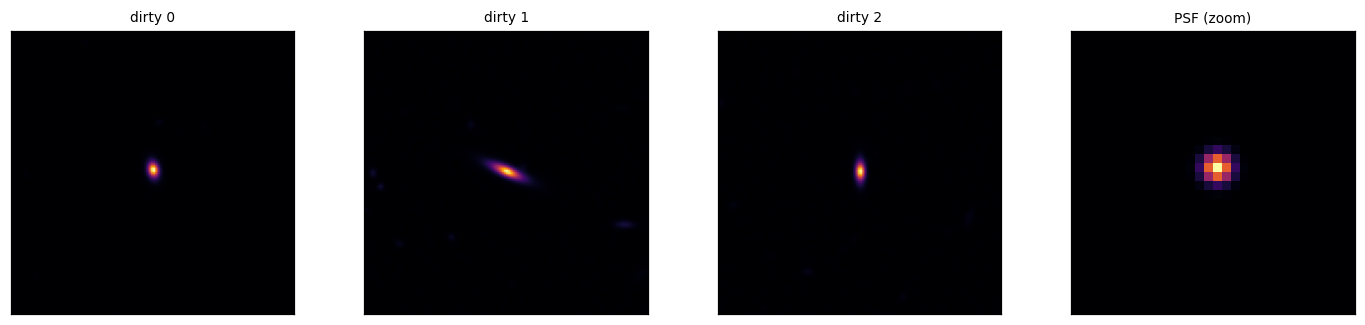

In [181]:
fig, ax = plt.subplots(1, 4, figsize=(13, 3))
for k in range(3):
    show(ax[k], dirty[k], f"dirty {k}")
show(ax[3], psf1[h-16:h+16, h-16:h+16], "PSF (zoom)")
plt.tight_layout(); plt.show()

In [182]:
from deepshape2.utils import load_config
from pathlib import Path

cfg = load_config()
WEIGHTS = Path("..") / "deepshape2" / "DS2_model_weights"
for name in ["drunet_blended.pt", "vae_mha.pt", "shape_network_full.pt", "eq_block.pt", "autoencoder_jit.pt"]:
    print(f"{name:25s}", "found" if (WEIGHTS / name).exists() else "MISSING")


drunet_blended.pt         found
vae_mha.pt                found
shape_network_full.pt     found
eq_block.pt               found
autoencoder_jit.pt        found


  niter=30, f1=0.380469, f2=3.70351, falpha=3.10972, SIGMA=7.1e-07


Reconstructing facets: 100%|##########################################################################################################################################| 2/2 [03:39<00:00, 109.83s/batch]


deconvolved (200, 128, 128) in 223 s


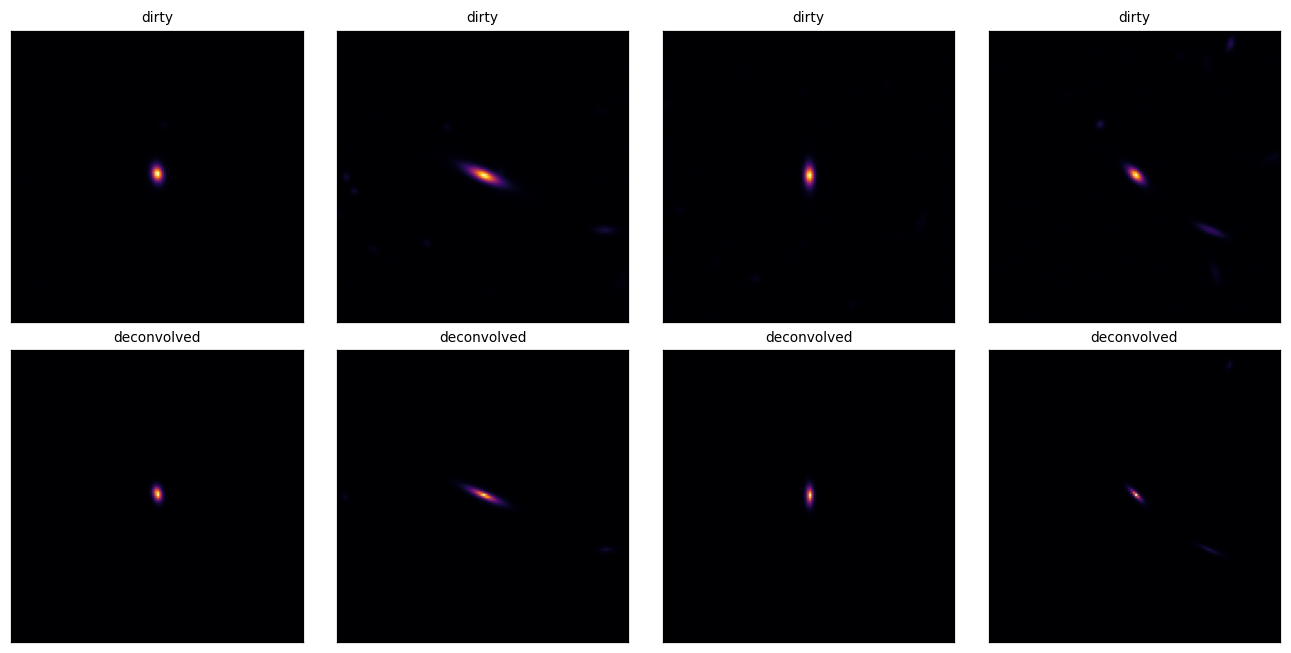

In [183]:
from deepshape2.reconstruction import reconstruct_facets

t = time.time()
result = reconstruct_facets(dirty, psf, device=DEVICE,
                            hqs_params={"path": WEIGHTS / "drunet_blended.pt"},
                            num_workers=0)
decon = result["recon"]
print(f"deconvolved {decon.shape} in {time.time() - t:.0f} s")

fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for k in range(4):
    show(ax[0, k], dirty[k], "dirty")
    show(ax[1, k], decon[k], "deconvolved")
plt.tight_layout(); plt.show()

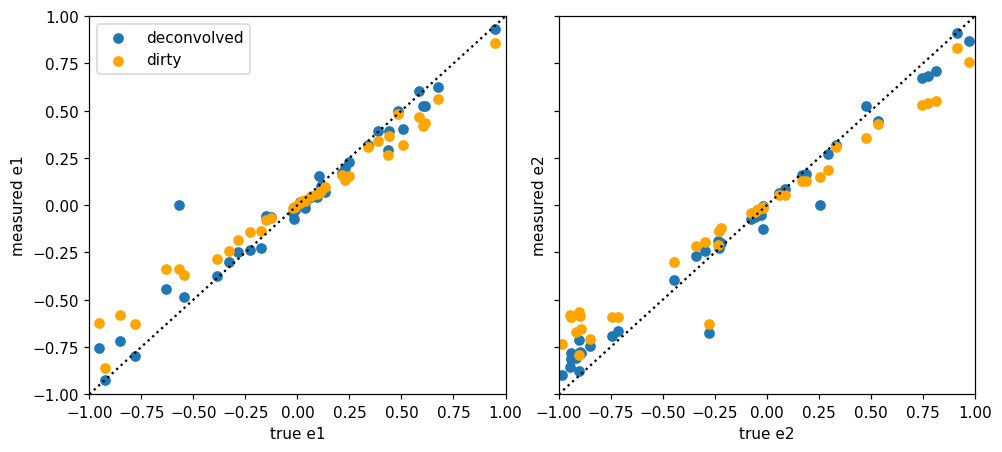

In [179]:
from deepshape2.utils import shape_galsim

e_decon, ok = shape_galsim(decon)

e_dirty, ok = shape_galsim(dirty)

e_true = np.array([[s.e1, s.e2] for s in (galsim.Shear(q=q, beta=-pa * galsim.degrees)
                   for q, pa in zip(gal["BMIN"] / gal["BMAJ"], gal["PA"]))])

fig, ax = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True, constrained_layout=True)
for k in range(2):
    ax[k].plot([-1, 1], [-1, 1], "k:")
    ax[k].scatter(e_true[ok, k], e_decon[ok, k], label="deconvolved")
    ax[k].scatter(e_true[ok, k], e_dirty[ok, k], color="orange", label ="dirty")
    ax[k].set(xlabel=f"true e{k+1}", ylabel=f"measured e{k+1}", xlim=(-1, 1), ylim=(-1, 1))
ax[0].legend()
plt.show()